# AI 05 — Ev tapşırığı

## Simple Linear Regression

İş təcrübəsinə görə əməkhaqqının proqnozlaşdırılması.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

## Tapşırıq 1 — Verilənlərin hazırlanması

In [3]:
x = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
y = np.array([650, 800, 950, 1100, 1300, 1450, 1600, 1800, 1950, 2150])

In [4]:
n = len(x)
n

10

In [5]:
print("İş təcrübəsi:", x)
print("Əməkhaqqı:", y)

İş təcrübəsi: [ 1  2  3  4  5  6  7  8  9 10]
Əməkhaqqı: [ 650  800  950 1100 1300 1450 1600 1800 1950 2150]


## Tapşırıq 2 — Xətti reqressiyanın riyazi hesablanması

$$
\hat{y} = a + bx
$$

$$
b = \frac{n\sum{xy} - \sum{x}\sum{y}}{n\sum{x^2} - (\sum{x})^2}
$$

$$
a = \frac{\sum{y} - b\sum{x}}{n}
$$

- $x$ — iş təcrübəsi
- $y$ — real əməkhaqqı
- $\hat{y}$ — proqnozlaşdırılan əməkhaqqı
- $a$ — sərbəst hədd (intercept)
- $b$ — meyl əmsalı (slope)
- $n$ — işçilərin sayı

In [6]:
b = (n*np.sum(x*y) - np.sum(x)*np.sum(y))/(n*np.sum(x**2) - np.sum(x)**2)

a = (np.sum(y) - b*np.sum(x))/n

In [7]:
print(f"Tənlik: y = {a:.2f} + {b:.2f}x")

Tənlik: y = 460.00 + 166.36x


### b əmsalının iqtisadi mənası

İş təcrübəsi 1 il artdıqda modelə əsasən proqnozlaşdırılan aylıq əməkhaqqı təxminən 166.36 AZN artır.

Sərbəst hədd 460 AZN-dir. Bu, sıfır il üçün modelin proqnozudur; verilənlərdə sıfır il yoxdur.

In [8]:
y_pred = a + b * x
print(np.round(y_pred, 2))

[ 626.36  792.73  959.09 1125.45 1291.82 1458.18 1624.55 1790.91 1957.27
 2123.64]


## Tapşırıq 3 — Scikit-learn ilə modelin qurulması

In [9]:
X = x.reshape(-1, 1)
X

array([[ 1],
       [ 2],
       [ 3],
       [ 4],
       [ 5],
       [ 6],
       [ 7],
       [ 8],
       [ 9],
       [10]])

In [10]:
model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[166.36]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,460
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[9.08]


In [11]:
a_sklearn = model.intercept_
b_sklearn = model.coef_[0]

In [12]:
print(f"Intercept: {a_sklearn:.2f}")
print(f"Slope: {b_sklearn:.2f}")
print(f"Tənlik: y = {a_sklearn:.2f} + {b_sklearn:.2f}x")

Intercept: 460.00
Slope: 166.36
Tənlik: y = 460.00 + 166.36x


In [13]:
print(f"Riyazi üsul: a = {a:.2f}, b = {b:.2f}")
print(f"Sklearn üsulu: a = {a_sklearn:.2f}, b = {b_sklearn:.2f}")

Riyazi üsul: a = 460.00, b = 166.36
Sklearn üsulu: a = 460.00, b = 166.36


### Nəticələrin müqayisəsi

Hər iki üsul eyni nəticə verir, çünki hər ikisi ən kiçik kvadratlar (OLS) üsuluna əsaslanır. Bu üsul real və proqnoz qiymətləri arasındakı xətaların kvadratları cəmini minimuma endirir.

In [14]:
y_pred_sklearn = model.predict(X)
print(np.round(y_pred_sklearn, 2))

[ 626.36  792.73  959.09 1125.45 1291.82 1458.18 1624.55 1790.91 1957.27
 2123.64]


## Tapşırıq 4 — Vizualizasiya

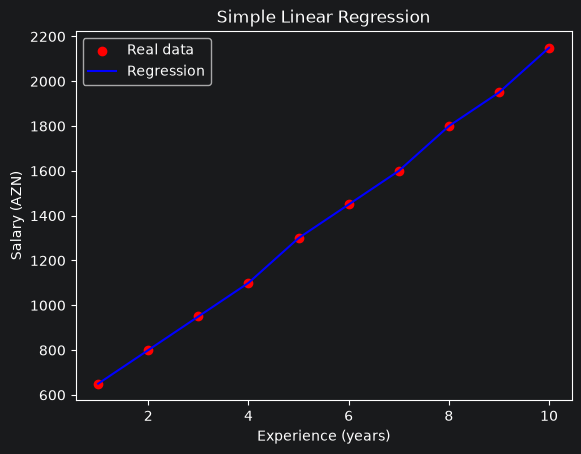

In [17]:
plt.scatter(x, y, color='red', label='Real data')
plt.plot(x, y, color='blue', label='Regression')
plt.xlabel('Experience (years)')
plt.ylabel('Salary (AZN)')
plt.title('Simple Linear Regression')
plt.legend()
plt.show()

## Tapşırıq 5 — Yeni proqnozların alınması

In [18]:
x_new = np.array([2.5, 4.5, 7.5, 12]).reshape(-1, 1)
y_new = model.predict(x_new)
print(np.round(y_new, 2))

[ 875.91 1208.64 1707.73 2456.36]


### Proqnoz nəticələri

| İş təcrübəsi (il) | Əməkhaqqı (AZN) |
|---|---:|
| 2.5 | 875.91 |
| 4.5 | 1208.64 |
| 7.5 | 1707.73 |
| 12 | 2456.36 |

In [20]:
while True:
    try:
        x_new = float(input("İş təcrübəsini daxil edin: "))
        if x_new == 0:
            print("Exit")
            break
        if x_new < 0:
            print("İş təcrübəsi mənfi ola bilməz")
            continue
        y_new = model.predict([[x_new]])[0]
        print(f"Proqnozlaşdırılan əməkhaqqı: {y_new:.2f} AZN")
    except KeyboardInterrupt:
        print("Proqram dayandırıldı")
        break

Proqnozlaşdırılan əməkhaqqı: 626.36 AZN
Proqnozlaşdırılan əməkhaqqı: 792.73 AZN
Proqnozlaşdırılan əməkhaqqı: 959.09 AZN
Proqram dayandırıldı


## Tapşırıq 6 — Nəticələrin təhlili

### 1. Xətti reqressiya nə üçün istifadə olunur?
Xətti əlaqəni öyrənmək və ədədi qiymətləri proqnozlaşdırmaq üçün istifadə olunur. Bu layihədə iş təcrübəsinə əsasən əməkhaqqını proqnozlaşdırırıq.

### 2. fit() və predict() metodları nə edir?
- fit() — verilənlər əsasında modeli öyrədir və əmsalları hesablayır.
- predict() — öyrədilmiş modellə proqnoz hesablayır.

### 3. coef_ və intercept_ arasında fərq nədir?
- coef_ — meyl əmsalıdır (166.36).
- intercept_ — sərbəst həddir (460.00), x sıfır olduqda modelin proqnozunu göstərir.

### 4. Nə üçün 12 illik iş təcrübəsi üçün proqnoza ehtiyatla yanaşmaq lazımdır?
Model 1–10 illik təcrübə məlumatları əsasında öyrədilib. 12 il bu aralıqdan kənardadır. Buna extrapolation deyilir və nəticə daha qeyri-müəyyəndir.

### 5. Yalnız iş təcrübəsindən istifadə etmək kifayətdirmi?
Xeyr. Əməkhaqqına təhsil, vəzifə, bacarıqlar, şirkət və iş sahəsi kimi amillər də təsir edir. Daha əhatəli proqnoz üçün əlavə xüsusiyyətlər və Multiple Linear Regression istifadə oluna bilər.